# Day 29 — JetRacer Vehicle Modelling

## Objective

Study and model the JetRacer vehicle platform as an autonomous-driving
vehicle interface.

The focus of this experiment is to understand:

- JetRacer vehicle architecture
- Sensor interface
- Steering interface
- Throttle interface
- Computing platform
- Autonomous-driving software interface
- Relationship between perception, planning, control, and vehicle actuation

This notebook uses a simplified software-level vehicle model and does
not directly command the physical vehicle.

## 1. JetRacer Platform Architecture

The JetRacer is considered as a vehicle platform consisting of:

1. Vehicle hardware
2. Computing platform
3. Sensor interface
4. Actuator interface
5. Autonomous-driving software

The simplified architecture is:

Camera
↓
Jetson Nano
↓
Perception
↓
Planning
↓
Control
↓
Steering / Throttle Interface
↓
Vehicle Actuation

In [1]:
vehicle = {
    "platform": "JetRacer Pro AI Kit",
    "compute": "NVIDIA Jetson Nano",
    "camera": "IMX219 CSI camera",
    "steering_interface": "car.steering",
    "throttle_interface": "car.throttle"
}

vehicle

{'platform': 'JetRacer Pro AI Kit',
 'compute': 'NVIDIA Jetson Nano',
 'camera': 'IMX219 CSI camera',
 'steering_interface': 'car.steering',
 'throttle_interface': 'car.throttle'}

## 2. Vehicle Interfaces

The JetRacer software interface provides two primary vehicle-actuation
commands:

- `car.steering` for steering control
- `car.throttle` for longitudinal vehicle control

The camera provides the primary perception input.

For this simplified model, steering and throttle commands are represented
using normalized values from -1 to +1.

In [2]:
steering_commands = [-1.0, -0.5, 0.0, 0.5, 1.0]
throttle_commands = [-1.0, -0.5, 0.0, 0.5, 1.0]

print("Steering command range:", min(steering_commands), "to", max(steering_commands))
print("Throttle command range:", min(throttle_commands), "to", max(throttle_commands))

Steering command range: -1.0 to 1.0
Throttle command range: -1.0 to 1.0


In [3]:
assert all(-1.0 <= value <= 1.0 for value in steering_commands)
assert all(-1.0 <= value <= 1.0 for value in throttle_commands)

print("Vehicle command range validation: PASSED")

Vehicle command range validation: PASSED


## 3. Camera Sensor Interface

The JetRacer uses a CSI camera as the primary perception input.

At the software level, the camera provides image data to the
autonomous-driving pipeline.

The simplified interface is:

Camera
↓
Image data
↓
Perception
↓
Planning / Control

The camera is therefore treated as a sensor input rather than an
actuation interface.

In [4]:
camera_interface = {
    "sensor": "IMX219 CSI camera",
    "interface": "camera.value",
    "data_type": "image",
    "role": "perception input"
}

print("Camera sensor:", camera_interface["sensor"])
print("Software interface:", camera_interface["interface"])
print("Data type:", camera_interface["data_type"])
print("Role:", camera_interface["role"])

Camera sensor: IMX219 CSI camera
Software interface: camera.value
Data type: image
Role: perception input


In [5]:
assert camera_interface["sensor"] == "IMX219 CSI camera"
assert camera_interface["data_type"] == "image"
assert camera_interface["role"] == "perception input"

print("Camera interface validation: PASSED")

Camera interface validation: PASSED


## 4. Steering and Throttle Interfaces

The JetRacer software provides normalized commands for vehicle
actuation.

The two primary interfaces are:

- `car.steering` — steering command
- `car.throttle` — longitudinal drive command

These commands form the interface between the autonomous-driving
software and the physical vehicle actuators.

The simplified interface is:

Steering Controller
↓
car.steering
↓
Steering actuator

Longitudinal Controller
↓
car.throttle
↓
Drive actuator

In [6]:
actuator_interfaces = {
    "steering": {
        "interface": "car.steering",
        "range": (-1.0, 1.0),
        "role": "steering control"
    },
    "throttle": {
        "interface": "car.throttle",
        "range": (-1.0, 1.0),
        "role": "longitudinal control"
    }
}

for actuator, interface in actuator_interfaces.items():
    print(f"{actuator.capitalize()} interface:")
    print("  Interface:", interface["interface"])
    print("  Range:", interface["range"])
    print("  Role:", interface["role"])

Steering interface:
  Interface: car.steering
  Range: (-1.0, 1.0)
  Role: steering control
Throttle interface:
  Interface: car.throttle
  Range: (-1.0, 1.0)
  Role: longitudinal control


In [7]:
for interface in actuator_interfaces.values():
    minimum, maximum = interface["range"]

    assert minimum == -1.0
    assert maximum == 1.0

print("Actuator interface validation: PASSED")

Actuator interface validation: PASSED


## 5. Autonomous-Driving Data Flow

The JetRacer vehicle interface can be connected to the autonomous-driving
pipeline developed during the previous learning stages.

The simplified data flow is:

Camera
↓
Perception
↓
Planning
↓
Control
↓
Vehicle Interface
↓
Steering / Throttle
↓
Vehicle

The vehicle interface therefore separates the autonomous-driving
software from the physical actuation layer.

In [8]:
autonomous_pipeline = [
    "Camera",
    "Perception",
    "Planning",
    "Control",
    "Vehicle Interface",
    "Vehicle Actuation"
]

for stage_number, stage in enumerate(autonomous_pipeline, start=1):
    print(f"{stage_number}. {stage}")

1. Camera
2. Perception
3. Planning
4. Control
5. Vehicle Interface
6. Vehicle Actuation


In [9]:
expected_pipeline = [
    "Camera",
    "Perception",
    "Planning",
    "Control",
    "Vehicle Interface",
    "Vehicle Actuation"
]

assert autonomous_pipeline == expected_pipeline

print("Autonomous-driving pipeline validation: PASSED")

Autonomous-driving pipeline validation: PASSED


## 6. Control-to-Vehicle Interface Mapping

The autonomous-driving controller generates vehicle commands.

For the simplified JetRacer interface:

- Lateral control produces a steering command.
- Longitudinal control produces a throttle command.

These commands are then mapped to the JetRacer actuator interfaces.

The mapping is:

Lateral Controller
↓
Steering Command
↓
car.steering

Longitudinal Controller
↓
Throttle Command
↓
car.throttle

In [10]:
control_output = {
    "lateral_control": {
        "output": "steering_command",
        "vehicle_interface": "car.steering"
    },
    "longitudinal_control": {
        "output": "throttle_command",
        "vehicle_interface": "car.throttle"
    }
}

for controller, mapping in control_output.items():
    print(f"{controller}:")
    print("  Controller output:", mapping["output"])
    print("  Vehicle interface:", mapping["vehicle_interface"])

lateral_control:
  Controller output: steering_command
  Vehicle interface: car.steering
longitudinal_control:
  Controller output: throttle_command
  Vehicle interface: car.throttle


In [11]:
assert control_output["lateral_control"]["vehicle_interface"] == "car.steering"
assert control_output["longitudinal_control"]["vehicle_interface"] == "car.throttle"

print("Control-to-vehicle interface mapping: PASSED")

Control-to-vehicle interface mapping: PASSED


## 7. Simplified JetRacer Vehicle Model

The JetRacer is represented using a simplified software-level vehicle
model.

The model contains:

- Computing platform
- Camera sensor
- Perception input
- Steering actuator interface
- Throttle actuator interface
- Autonomous-driving software pipeline

This model describes the interfaces required for autonomous-driving
software integration.

It does not represent detailed electrical architecture, motor
dynamics, steering geometry, tire forces, or vehicle dynamics.

In [12]:
jetracer_model = {
    "vehicle": {
        "platform": "JetRacer Pro AI Kit",
        "compute": "NVIDIA Jetson Nano"
    },
    "sensors": {
        "camera": {
            "hardware": "IMX219 CSI camera",
            "software_interface": "camera.value",
            "data": "image"
        }
    },
    "actuators": {
        "steering": {
            "software_interface": "car.steering",
            "command_range": (-1.0, 1.0)
        },
        "throttle": {
            "software_interface": "car.throttle",
            "command_range": (-1.0, 1.0)
        }
    },
    "pipeline": [
        "Perception",
        "Planning",
        "Control",
        "Vehicle Interface"
    ]
}

jetracer_model

{'vehicle': {'platform': 'JetRacer Pro AI Kit',
  'compute': 'NVIDIA Jetson Nano'},
 'sensors': {'camera': {'hardware': 'IMX219 CSI camera',
   'software_interface': 'camera.value',
   'data': 'image'}},
 'actuators': {'steering': {'software_interface': 'car.steering',
   'command_range': (-1.0, 1.0)},
  'throttle': {'software_interface': 'car.throttle',
   'command_range': (-1.0, 1.0)}},
 'pipeline': ['Perception', 'Planning', 'Control', 'Vehicle Interface']}

In [13]:
assert jetracer_model["vehicle"]["platform"] == "JetRacer Pro AI Kit"
assert jetracer_model["vehicle"]["compute"] == "NVIDIA Jetson Nano"

assert jetracer_model["sensors"]["camera"]["software_interface"] == "camera.value"
assert jetracer_model["sensors"]["camera"]["data"] == "image"

assert jetracer_model["actuators"]["steering"]["software_interface"] == "car.steering"
assert jetracer_model["actuators"]["throttle"]["software_interface"] == "car.throttle"

assert jetracer_model["actuators"]["steering"]["command_range"] == (-1.0, 1.0)
assert jetracer_model["actuators"]["throttle"]["command_range"] == (-1.0, 1.0)

print("Integrated JetRacer vehicle model validation: PASSED")

Integrated JetRacer vehicle model validation: PASSED


## 8. JetRacer Autonomous-Driving Architecture

The following diagram represents the simplified relationship between
the JetRacer sensor, computing platform, autonomous-driving software,
and vehicle-actuation interfaces.

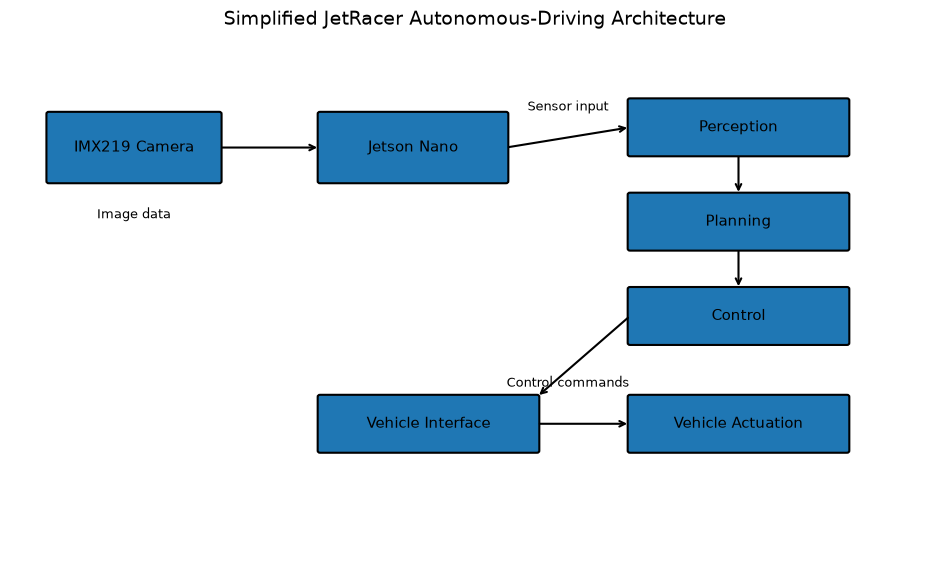

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 7))

ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

boxes = [
    (0.5, 5.8, 2.2, 1.0, "IMX219 Camera"),
    (4.0, 5.8, 2.4, 1.0, "Jetson Nano"),
    (8.0, 6.2, 2.8, 0.8, "Perception"),
    (8.0, 4.8, 2.8, 0.8, "Planning"),
    (8.0, 3.4, 2.8, 0.8, "Control"),
    (4.0, 1.8, 2.8, 0.8, "Vehicle Interface"),
    (8.0, 1.8, 2.8, 0.8, "Vehicle Actuation"),
]

for x, y, width, height, label in boxes:
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.03",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        y + height / 2,
        label,
        ha="center",
        va="center",
        fontsize=11
    )

arrows = [
    ((2.7, 6.3), (4.0, 6.3)),
    ((6.4, 6.3), (8.0, 6.6)),
    ((9.4, 6.2), (9.4, 5.6)),
    ((9.4, 4.8), (9.4, 4.2)),
    ((8.0, 3.8), (6.8, 2.6)),
    ((6.8, 2.2), (8.0, 2.2)),
]

for start, end in arrows:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(arrowstyle="->", linewidth=1.5)
    )

ax.text(
    1.6,
    5.25,
    "Image data",
    ha="center",
    fontsize=9
)

ax.text(
    7.2,
    6.85,
    "Sensor input",
    ha="center",
    fontsize=9
)

ax.text(
    7.2,
    2.75,
    "Control commands",
    ha="center",
    fontsize=9
)

ax.set_title(
    "Simplified JetRacer Autonomous-Driving Architecture",
    fontsize=14
)

plt.show()

## 9. Final Validation

The Day 29 vehicle model is considered valid when:

- JetRacer platform information is represented.
- Camera sensor interface is defined.
- Steering interface is defined.
- Throttle interface is defined.
- Normalized actuator command ranges are validated.
- Autonomous-driving data flow is represented.
- Control outputs are mapped to vehicle interfaces.
- The integrated vehicle model passes validation.
- The architecture diagram is generated successfully.

In [15]:
validation_results = {
    "platform_model": True,
    "camera_interface": True,
    "steering_interface": True,
    "throttle_interface": True,
    "command_range_validation": True,
    "autonomous_pipeline": True,
    "control_interface_mapping": True,
    "integrated_vehicle_model": True,
    "architecture_visualization": True
}

assert all(validation_results.values())

print("======================================")
print("DAY 29 FINAL VALIDATION")
print("======================================")

for item, result in validation_results.items():
    print(f"{item}: {'PASSED' if result else 'FAILED'}")

print("--------------------------------------")
print("Day 29 JetRacer vehicle model: PASSED")
print("======================================")

DAY 29 FINAL VALIDATION
platform_model: PASSED
camera_interface: PASSED
steering_interface: PASSED
throttle_interface: PASSED
command_range_validation: PASSED
autonomous_pipeline: PASSED
control_interface_mapping: PASSED
integrated_vehicle_model: PASSED
architecture_visualization: PASSED
--------------------------------------
Day 29 JetRacer vehicle model: PASSED
